In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler

In [70]:
np.random.seed(42)

data_size = 50
experience = np.random.randint(1,21, size=data_size)
education = np.random.randint(1,5, size=data_size)

noise = np.random.normal(0, 500000, size=data_size)
salary = np.round(1000000 * experience + 500000 * education + noise).astype(int)

df = pd.DataFrame({
    "Experience" : experience,
    "Education" : education,
    "Salary" : salary
})

df.head()

,Experience,Education,Salary
0,7,4,8661539
1,20,4,22305838
2,15,2,16515500
3,11,2,12465640
4,8,2,8580391


In [71]:
x = df[["Experience", "Education"]] # fitur
y = df[["Salary"]] # target

scaler_x = MinMaxScaler()
x_scaled = scaler_x.fit_transform(x)

scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y_scaled, test_size=0.3, random_state=42)

In [72]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

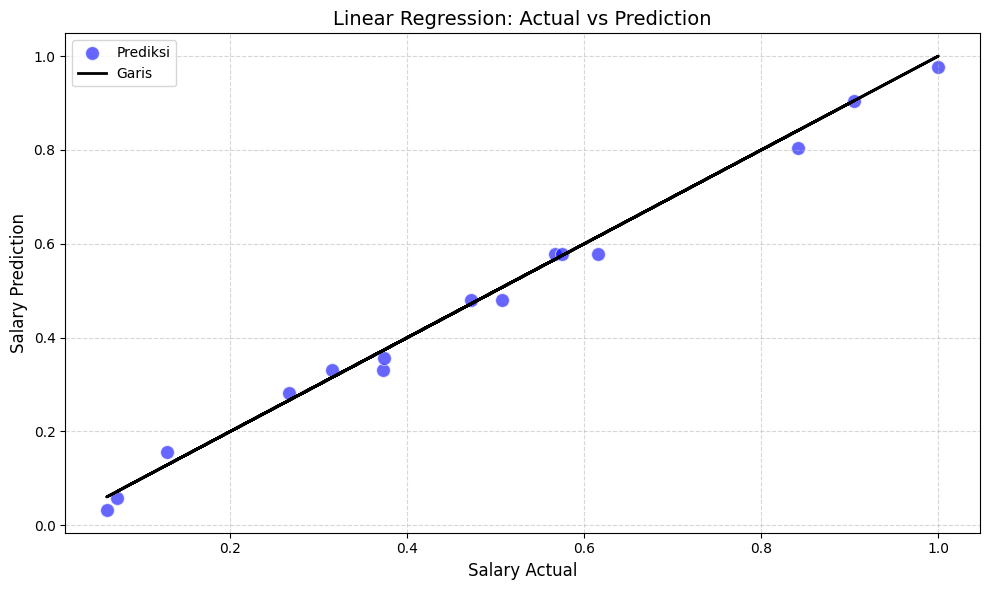

In [73]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, color = "blue", alpha = 0.6, s = 100, label = "Prediksi")
plt.plot(y_test, y_test, color = "black", linewidth = 2, label="Garis")
plt.xlabel("Salary Actual", fontsize = 12)
plt.ylabel("Salary Prediction", fontsize = 12)
plt.title("Linear Regression: Actual vs Prediction", fontsize = 14)
plt.legend()
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

In [74]:
model.score(x_test, y_test)

0.992814325133279

DATA BARU

In [75]:
new_data = pd.DataFrame({
    "Experience" : [1,10,5],
    "Education" : [1,2,2]
})

new_data_scaled = scaler_x.transform(new_data)

prediction_norm = model.predict(new_data_scaled)
prediction = scaler_y.inverse_transform(prediction_norm.reshape(-1,1))

new_data["Salary"] = np.round(prediction.flatten()).astype(int)
new_data

,Experience,Education,Salary
0,1,1,1332625
1,10,2,10928150
2,5,2,5871047


In [76]:
new_data = pd.DataFrame({
    "Experience" : [1,10,5],
    "Education" : [1,2,2]
})

new_data_scaled = scaler_x.transform(new_data)

prediction_norm = model.predict(new_data_scaled)
prediction_norm

array([-0.0417757 ,  0.4308287 ,  0.18175329])

In [77]:
prediction_norm.reshape(-1,1)

array([[-0.0417757 ],
       [ 0.4308287 ],
       [ 0.18175329]])

In [78]:
prediction = scaler_y.inverse_transform(prediction_norm.reshape(-1,1))
prediction

array([[ 1332624.81195457],
       [10928150.30069915],
       [ 5871046.63752511]])

In [79]:
prediction.flatten()

array([ 1332624.81195457, 10928150.30069915,  5871046.63752511])

In [80]:
np.round(prediction.flatten())

array([ 1332625., 10928150.,  5871047.])

In [81]:
np.round(prediction.flatten()).astype(int)

array([ 1332625, 10928150,  5871047])

In [82]:
new_data["Salary"] = np.round(prediction.flatten()).astype(int)
new_data

,Experience,Education,Salary
0,1,1,1332625
1,10,2,10928150
2,5,2,5871047


ASSIGNMENT

In [83]:
# No 1

import pandas as pd

covid = pd.read_csv("covid19.csv")
covid

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,NaN,0,NaN,0
...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,NaN,5740
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,NaN,266387,NaN,5740
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,NaN,266387,NaN,5740
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,NaN,266387,NaN,5740


In [84]:
# No 2

covid.isnull().sum()

Date_reported            0
Country_code           244
Country                  0
Continent                0
WHO_region            4392
New_cases            19300
Cumulative_cases         0
New_deaths           33476
Cumulative_deaths        0
dtype: int64

In [85]:
covid.fillna(0, inplace=True)

In [86]:
covid.isnull().sum()

Date_reported        0
Country_code         0
Country              0
Continent            0
WHO_region           0
New_cases            0
Cumulative_cases     0
New_deaths           0
Cumulative_deaths    0
dtype: int64

In [87]:
covid.drop_duplicates(inplace=True)

In [88]:
q1 = covid["Cumulative_deaths"].quantile(0.25)
q3 = covid["Cumulative_deaths"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr 

df_clean = covid[(covid["Cumulative_deaths"] >= lower) & (covid["Cumulative_deaths"] <= upper)]
df_clean

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,0.0,5740
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740


In [89]:
# No 3 dan No 4

x = df_clean[["Country_code", "Cumulative_cases", "New_deaths"]]
y = df_clean[["Cumulative_deaths"]]

# one hot encoding
x = pd.get_dummies(x, columns=["Country_code"], drop_first=True)

# normalisasi
scaler_fitur = MinMaxScaler()
x[["Cumulative_cases", "New_deaths"]] = scaler_fitur.fit_transform(x[["Cumulative_cases", "New_deaths"]])

scaler_target = MinMaxScaler()
y_norm = scaler_target.fit_transform(y).ravel() # data target harus 1 dimensi

# data splitting

x_train, x_test, y_train, y_test = train_test_split(x, y_norm, test_size=0.2, random_state=42)

print(f"training x : {len(x_train)}, testing x : {len(x_test)}")
print(f"training y : {len(y_train)}, testing y : {len(y_test)}")

training x : 39475, testing x : 9869
training y : 39475, testing y : 9869


In [90]:
# No 5

model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([ 0.00332536,  0.32970279,  0.00135243, ...,  0.5987371 ,
       -0.0053801 ,  0.41065222])

In [91]:
# No 6

model.score(x_test, y_test)

0.7616201115944176

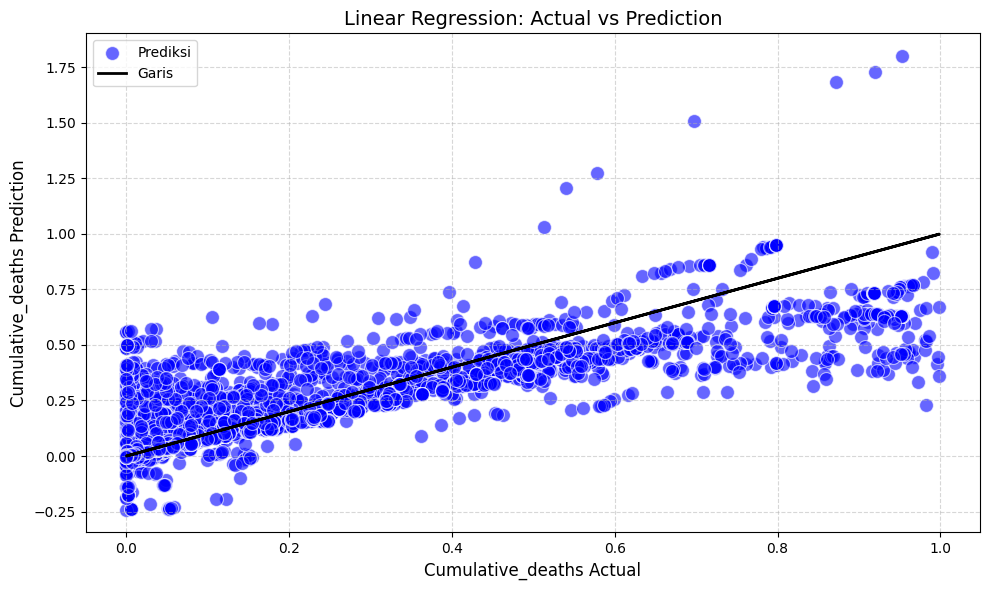

In [92]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, color = "blue", alpha = 0.6, s = 100, label = "Prediksi")
plt.plot(y_test, y_test, color = "black", linewidth = 2, label="Garis")
plt.xlabel("Cumulative_deaths Actual", fontsize = 12)
plt.ylabel("Cumulative_deaths Prediction", fontsize = 12)
plt.title("Linear Regression: Actual vs Prediction", fontsize = 14)
plt.legend()
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()